# Hospital Readmission Analysis: Patients with Diabetes

## Project Overview

This project examines hospital readmission patterns among patients with diabetes using the UCI Diabetes 130-US Hospitals dataset (1999–2008), which contains 101,766 hospital encounters.

The analysis uses Python to explore how patient characteristics, clinical diagnoses, hospital encounter factors, and previous healthcare utilization relate to readmission within 30 days.

## Main Research Question

**What patient characteristics and hospital encounter factors are associated with readmission within 30 days among patients with diabetes?**

## Analysis Objectives

1. **Measure the overall 30-day readmission rate:** Determine the percentage of all hospital encounters followed by readmission within 30 days.

2. **Identify characteristics associated with readmission:** Examine which patient characteristics and hospital encounter factors are associated with higher or lower 30-day readmission rates.

## Analytical Approach

The project includes data exploration, cleaning and validation, ICD-9-CM diagnosis classification, exploratory data analysis, and visualization.

Readmission rates are calculated at the hospital encounter level, and findings are interpreted as descriptive associations rather than causal relationships.


## Data Loading and Initial Exploration


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path

In [2]:

df = pd.read_csv("data/diabetic_data.csv")

df.head()


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:

df.shape


(101766, 50)

In [4]:

df.columns.tolist()


['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'weight',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'payer_code',
 'medical_specialty',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'diag_1',
 'diag_2',
 'diag_3',
 'number_diagnoses',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted']

In [5]:

df["encounter_id"].nunique()


101766

In [6]:

df["patient_nbr"].nunique()


71518

### Repeated Patient Encounters

Which patients have the highest number of recorded encounters?


In [7]:

df["patient_nbr"].value_counts().head(10)


patient_nbr
88785891    40
43140906    28
1660293     23
88227540    23
23199021    23
23643405    22
84428613    22
92709351    21
88789707    20
29903877    20
Name: count, dtype: int64

In [8]:

df["readmitted"].value_counts()


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [9]:

df["readmitted"].value_counts(normalize=True) * 100


readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

### Column Data Types

What data types are present in the dataset?


In [10]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

### Missing Values

Which columns have missing values?


In [11]:

df.isna().sum().sort_values(ascending=False)


max_glu_serum               96420
A1Cresult                   84748
encounter_id                    0
nateglinide                     0
glimepiride                     0
acetohexamide                   0
glipizide                       0
glyburide                       0
tolbutamide                     0
pioglitazone                    0
rosiglitazone                   0
acarbose                        0
miglitol                        0
troglitazone                    0
tolazamide                      0
examide                         0
citoglipton                     0
insulin                         0
glyburide-metformin             0
glipizide-metformin             0
glimepiride-pioglitazone        0
metformin-rosiglitazone         0
metformin-pioglitazone          0
change                          0
diabetesMed                     0
chlorpropamide                  0
repaglinide                     0
patient_nbr                     0
medical_specialty               0
race          

### Placeholder Values

Are missing values represented by `?`?


In [12]:

(df == "?").sum().sort_values(ascending=False).head(15)


weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
encounter_id             0
tolazamide               0
glyburide                0
tolbutamide              0
pioglitazone             0
rosiglitazone            0
acarbose                 0
miglitol                 0
dtype: int64

### Duplicate Records

Are any encounter identifiers or rows duplicated?


In [13]:

print("Fully duplicated rows:", df.duplicated().sum())

print(
    "Duplicated encounter IDs:",
    df["encounter_id"].duplicated().sum()
)


Fully duplicated rows: 0
Duplicated encounter IDs: 0


### Value Ranges and Outliers

Are there unusually high or potentially implausible numeric values?


In [14]:

columns_to_check = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

df[columns_to_check].describe()


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000


In [15]:
df[["num_medications", "num_lab_procedures"]].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)


,num_medications,num_lab_procedures
count,101766.000000,101766.000000
mean,16.021844,43.095641
std,8.127566,19.674362
min,1.000000,1.000000
50%,15.000000,44.000000
75%,20.000000,57.000000
90%,26.000000,67.000000
95%,31.000000,73.000000
99%,43.000000,85.000000
max,81.000000,132.000000


In [16]:

print(
    "Encounters with 60+ medications:",
    (df["num_medications"] >= 60).sum()
)

print(
    "Encounters with 100+ lab tests:",
    (df["num_lab_procedures"] >= 100).sum()
)


Encounters with 60+ medications: 120
Encounters with 100+ lab tests: 77


In [17]:

df.nlargest(10, "num_medications")[
    [
        "encounter_id",
        "time_in_hospital",
        "num_medications",
        "num_lab_procedures",
        "number_diagnoses",
        "readmitted"
    ]
]


,encounter_id,time_in_hospital,num_medications,num_lab_procedures,number_diagnoses,readmitted
43877,135412542,10,81,57,6,<30
44696,137878980,12,79,57,8,NO
46892,144470340,10,75,61,8,NO
75485,226403562,7,75,76,9,NO
64808,180371094,13,74,62,7,NO
56106,161465688,13,72,73,9,<30
69367,197017632,14,72,85,9,<30
71264,206199168,11,72,68,9,<30
29572,96505416,13,70,52,8,>30
46921,144496446,11,70,59,9,<30


### Data Quality Decision: Unusual Values

High values in `num_medications` and `num_lab_procedures` were retained because they were unusual but not confirmed to be errors. Their influence should be reassessed if they materially affect the analysis.


In [18]:

for col in ["gender", "age", "readmitted"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))



gender
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

age
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

readmitted
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


## Data Cleaning and Validation


In [19]:

df_clean = df.copy()


In [20]:

df_clean["gender"] = df_clean["gender"].replace(
    "Unknown/Invalid", pd.NA
)

df_clean["gender"].value_counts(dropna=False)


gender
Female    54708
Male      47055
<NA>          3
Name: count, dtype: int64

In [21]:

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))

print(
    "Unknown gender values remaining:",
    (df_clean["gender"] == "Unknown/Invalid").sum()
)

print(
    "Missing gender values:",
    df_clean["gender"].isna().sum()
)


Original rows: 101766
Cleaned rows: 101766
Unknown gender values remaining: 0
Missing gender values: 3


In [22]:

question_mark_counts = (
    df_clean.astype("string")
    .eq("?")
    .sum()
    .sort_values(ascending=False)
)

question_mark_counts[question_mark_counts > 0]


weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: Int64

In [23]:

# Columns using "?" to represent missing data
missing_columns = [ "weight", "medical_specialty", "payer_code", "race", "diag_1", "diag_2", "diag_3"]

#  Standardize missing values
df_clean[missing_columns] = (
    df_clean[missing_columns].replace("?", pd.NA)
)


In [24]:

# Confirm no question marks remain
print(
    "Remaining question marks:",
    df_clean[missing_columns].eq("?").sum().sum()
)

# Check missing values by column
print(
    df_clean[missing_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

# Confirm row count
print("Total rows:", len(df_clean))



Remaining question marks: 0
weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64
Total rows: 101766


#### Data Cleaning Decision: Weight

The `weight` variable was excluded from the primary 30-day readmission analysis because approximately 96.9% of encounter records lack weight information. Analyzing only records with documented weight could introduce selection bias and produce findings that are not representative of the overall dataset.

The variable was retained in the cleaned dataset for transparency and potential future analysis. No encounters were removed because of missing weight values.


In [25]:

# Variables excluded from the primary analysis
excluded_from_analysis = ["weight"]

# Confirm weight is preserved
print("Weight in cleaned dataset:", "weight" in df_clean.columns)


Weight in cleaned dataset: True


In [26]:

# Examine payer categories, including missing values
df_clean["payer_code"].value_counts(dropna=False)


payer_code
<NA>    40256
MC      32439
HM       6274
SP       5007
BC       4655
MD       3532
CP       2533
UN       2448
CM       1937
OG       1033
PO        592
DM        549
CH        146
WC        135
OT         95
MP         79
SI         55
FR          1
Name: count, dtype: int64

In [27]:

payer_available = (
    df_clean["payer_code"].notna().mean() * 100
)

print(f"Payer information available: {payer_available:.2f}%")


Payer information available: 60.44%


In [28]:

pd.crosstab(
    df_clean["payer_code"].isna(),
    df_clean["readmitted"],
    normalize="index"
) * 100


readmitted,<30,>30,NO
payer_code,,,
False,10.941310,35.306454,53.752235
True,11.493939,34.350159,54.155902


In [29]:

diagnosis_cols = ["diag_1", "diag_2", "diag_3"]

# Count missing diagnoses
df_clean[diagnosis_cols].isna().sum()


diag_1      21
diag_2     358
diag_3    1423
dtype: int64

In [30]:

# Examine the most frequent primary diagnoses
df_clean["diag_1"].value_counts().head(10)


diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64

In [31]:

reference_path = Path("references/I9diagnosesV25.txt")

# Read the reference as text
with open(reference_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

# Separate each code from its description
records = [line.strip().split(maxsplit=1) for line in lines]

icd_reference = pd.DataFrame(
    records,
    columns=["icd9_code", "description"]
)

icd_reference.head(10)


,icd9_code,description
0,0010,CHOLERA D/T VIB CHOLERAE
1,0011,CHOLERA D/T VIB EL TOR
2,0019,CHOLERA NOS
3,0020,TYPHOID FEVER
4,0021,PARATYPHOID FEVER A
5,0022,PARATYPHOID FEVER B
6,0023,PARATYPHOID FEVER C
7,0029,PARATYPHOID FEVER NOS
8,0030,SALMONELLA ENTERITIS
9,0031,SALMONELLA SEPTICEMIA


In [32]:

icd_reference[
    icd_reference["icd9_code"].str[:3].isin(
        ["428", "414", "786", "410", "486"]
    )
].groupby(
    icd_reference["icd9_code"].str[:3]
).size()


icd9_code
410    30
414    15
428    15
486     1
786    21
dtype: int64

In [33]:

# Inspect diagnosis code formats
print("Hospital diagnosis codes:")
print(df_clean["diag_1"].dropna().unique()[:20])

print("\nCMS reference codes:")
print(icd_reference["icd9_code"].head(20).tolist())


Hospital diagnosis codes:
['250.83' '276' '648' '8' '197' '414' '428' '398' '434' '250.7' '157'
 '518' '999' '410' '682' '402' '737' '572' 'V57' '189']

CMS reference codes:
['0010', '0011', '0019', '0020', '0021', '0022', '0023', '0029', '0030', '0031', '00320', '00321', '00322', '00323', '00324', '00329', '0038', '0039', '0040', '0041']


In [34]:

common_codes = ["428", "414", "786", "410", "486"]

for code in common_codes:
    exact_match = (
        icd_reference["icd9_code"] == code
    ).any()

    print(f"{code}: Exact match = {exact_match}")


428: Exact match = False
414: Exact match = False
786: Exact match = False
410: Exact match = False
486: Exact match = True


In [35]:

# Create a formatted code for matching
df_clean["diag_1_match"] = (
    df_clean["diag_1"]
    .astype("string")
    .str.strip()
    .str.replace(".", "", regex=False)
)

# Inspect the original and formatted codes
df_clean[["diag_1", "diag_1_match"]].head(15)


,diag_1,diag_1_match
0,250.83,25083
1,276,276
2,648,648
3,8,8
4,197,197
5,414,414
6,414,414
7,428,428
8,398,398
9,434,434


In [36]:

# Compare formatted codes against CMS reference
exact_matches = df_clean["diag_1_match"].isin(
    icd_reference["icd9_code"]
)

print("Exact matches:", exact_matches.sum())
print("Non-matches:", (~exact_matches & df_clean["diag_1_match"].notna()).sum())
print("Missing diagnosis codes:", df_clean["diag_1_match"].isna().sum())


Exact matches: 9050
Non-matches: 92695
Missing diagnosis codes: 21


In [37]:

# Count unique primary diagnosis codes
print(
    "Unique primary diagnosis codes:",
    df_clean["diag_1_match"].nunique()
)

# Show the 15 most common unmatched codes
unmatched_codes = df_clean.loc[
    df_clean["diag_1_match"].notna()
    & ~df_clean["diag_1_match"].isin(
        icd_reference["icd9_code"]
    ),
    "diag_1_match"
]

unmatched_codes.value_counts().head(15)


Unique primary diagnosis codes: 716


diag_1_match
428     6862
414     6581
786     4016
410     3614
427     2766
491     2275
715     2151
682     2042
434     2028
780     2019
996     1967
276     1889
38      1688
2508    1680
599     1595
Name: count, dtype: Int64

In [38]:

# Examine original diagnosis codes behind
# the unusual formatted values

df_clean.loc[
    df_clean["diag_1_match"].isin(["38", "2508"]),
    ["diag_1", "diag_1_match"]
].value_counts()


diag_1  diag_1_match
38      38              1688
250.8   2508            1680
Name: count, dtype: int64

In [39]:

# Find numeric diagnosis codes that have fewer than 3 digits
short_codes = (
    df_clean["diag_1"]
    .dropna()
    .astype("string")
    .str.strip()
)

short_codes = short_codes[
    short_codes.str.fullmatch(r"\d{1,2}")
]

short_codes.value_counts()


diag_1
38    1688
8      515
79      86
53      55
9       46
70      46
42      45
47      26
3       13
54      12
11      10
35      10
78       9
5        9
88       9
41       8
94       7
82       7
34       7
66       6
49       5
31       3
23       2
36       2
52       2
58       2
48       2
27       2
75       2
39       2
7        2
61       1
57       1
97       1
98       1
84       1
10       1
Name: count, dtype: Int64

In [40]:

# Use the original primary diagnosis values
diagnoses = df_clean["diag_1"].astype("string").str.strip()

# Identify codes containing only 1 or 2 digits
short_codes = diagnoses.str.fullmatch(r"\d{1,2}").fillna(False)

total_encounters = len(df_clean)
short_count = short_codes.sum()
missing_count = diagnoses.isna().sum()

print("Total encounters:", total_encounters)
print("Encounters with 1-2 digit codes:", short_count)
print(f"Percentage with short codes: {short_count / total_encounters * 100:.2f}%")
print("Missing primary diagnoses:", missing_count)
print(
    f"Remaining encounters: "
    f"{total_encounters - short_count - missing_count}"
)


Total encounters: 101766
Encounters with 1-2 digit codes: 2646
Percentage with short codes: 2.60%
Missing primary diagnoses: 21
Remaining encounters: 99099


In [41]:

# Categorize diagnosis code formats without changing them
code_format = pd.Series("Other / review", index=df_clean.index)

code_format.loc[diagnoses.isna()] = "Missing"
code_format.loc[
    diagnoses.str.fullmatch(r"\d{1,2}").fillna(False)
] = "1-2 digit numeric"
code_format.loc[
    diagnoses.str.fullmatch(r"\d{3}(?:\.\d{1,2})?").fillna(False)
] = "3-digit or more specific numeric"
code_format.loc[
    diagnoses.str.fullmatch(r"[VE]\d+(?:\.\d+)?").fillna(False)
] = "V or E code"

# Show counts and percentages
format_summary = pd.DataFrame({
    "encounters": code_format.value_counts()
})

format_summary["percent"] = (
    format_summary["encounters"] / len(df_clean) * 100
).round(2)

format_summary


,encounters,percent
3-digit or more specific numeric,97454,95.76
1-2 digit numeric,2646,2.60
V or E code,1645,1.62
Missing,21,0.02


In [42]:

# Use the original diagnosis values
codes = df_clean["diag_1"].astype("string").str.strip()

# Identify numeric codes with at least 3 digits
valid_numeric_format = codes.str.fullmatch(
    r"\d{3}(?:\.\d{1,2})?"
).fillna(False)

# Extract the 3-digit family without changing the original
code_families = codes.str[:3]

# Get recognized 3-digit families from the CMS reference
cms_families = set(
    icd_reference["icd9_code"].str[:3]
)

# Check whether each numeric code's family exists
family_matches = valid_numeric_format & (
    code_families.isin(cms_families)
)

print("Numeric encounters checked:",
      valid_numeric_format.sum())

print("Recognized CMS families:",
      family_matches.sum())

print("Unrecognized numeric families:",
      (valid_numeric_format & ~family_matches).sum())

print(
    "Percentage of numeric encounters recognized:",
    round(
        family_matches.sum()
        / valid_numeric_format.sum() * 100,
        2
    )
)


Numeric encounters checked: 97454
Recognized CMS families: 97454
Unrecognized numeric families: 0
Percentage of numeric encounters recognized: 100.0


### Diagnosis Code Validation and Classification Methodology

**Objective:** To group primary diagnosis codes (`diag_1`) into clinically meaningful categories for analyzing their association with 30-day hospital readmission.

**Reference:** CMS ICD-9-CM Diagnosis Code Descriptions, Version 25 (effective October 1, 2007), using `I9diagnosesV25.txt`.

**Validation findings:**

- The dataset contains **101,766 hospital encounters** and **716 unique non-missing primary diagnosis values**.
- **97,454 encounters (95.76%)** contain numeric primary diagnosis codes with at least three digits.
- All 97,454 eligible encounters matched a recognized three-digit diagnosis family in the CMS reference (**100% family-level recognition**).
- **2,646 encounters (2.60%)** contain one- or two-digit numeric codes that cannot be reliably interpreted without further documentation.
- **1,645 encounters (1.62%)** contain V or E codes, which require separate classification rules.
- **21 encounters (0.02%)** have missing primary diagnosis information.

**Classification approach:**

Primary diagnosis codes will be grouped using the official ICD-9-CM chapter ranges, such as circulatory system diseases, respiratory system diseases, and endocrine, nutritional, and metabolic diseases.

The CMS reference is used to verify that numeric diagnosis families are recognized. The official ICD-9-CM chapter structure is used to assign broader clinical categories. This approach allows meaningful comparisons without assigning diagnoses more specific than the original data supports.

The original diagnosis values will be preserved. No leading zeros or additional digits will be added to abbreviated codes.

**Limitations:**

- Family-level recognition does not confirm the validity of every complete diagnosis code.
- One- and two-digit numeric codes will remain unclassified unless additional documentation supports their interpretation.
- V and E codes will be handled separately.
- The CMS reference is from 2007, while the hospital dataset covers 1999–2008, so historical coding differences may exist.

**Analytical decision:**

Primary diagnosis categories will be **retained in the planned 30-day readmission analysis**, subject to successful classification and validation. Unclassified and missing diagnoses will be reported separately rather than silently excluded.

Readmission rates will be compared across broad clinical categories to identify associations, not establish causation.

In [43]:


def classify_diagnosis(code):
    if pd.isna(code):
        return "Missing"

    code = str(code).strip()

    # Preserve special ICD-9 code families
    if code.startswith("V"):
        return "V codes"
    if code.startswith("E"):
        return "E codes"

    # Validate numeric ICD-9 format
    if not re.fullmatch(r"\d{3}(?:\.\d{1,2})?", code):
        return "Unclassified"

    # Confirm family exists in CMS reference
    if code[:3] not in cms_families:
        return "Unclassified"

    category = int(code[:3])

    if 1 <= category <= 139:
        return "Infectious and parasitic diseases"
    elif 140 <= category <= 239:
        return "Neoplasms"
    elif 240 <= category <= 279:
        return "Endocrine and metabolic diseases"
    elif 280 <= category <= 289:
        return "Blood disorders"
    elif 290 <= category <= 319:
        return "Mental disorders"
    elif 320 <= category <= 389:
        return "Nervous system and sense organs"
    elif 390 <= category <= 459:
        return "Circulatory system diseases"
    elif 460 <= category <= 519:
        return "Respiratory system diseases"
    elif 520 <= category <= 579:
        return "Digestive system diseases"
    elif 580 <= category <= 629:
        return "Genitourinary system diseases"
    elif 630 <= category <= 679:
        return "Pregnancy and childbirth"
    elif 680 <= category <= 709:
        return "Skin and subcutaneous diseases"
    elif 710 <= category <= 739:
        return "Musculoskeletal diseases"
    elif 740 <= category <= 759:
        return "Congenital anomalies"
    elif 760 <= category <= 779:
        return "Perinatal conditions"
    elif 780 <= category <= 799:
        return "Symptoms and ill-defined conditions"
    elif 800 <= category <= 999:
        return "Injury and poisoning"
    else:
        return "Unclassified"


In [44]:
cms_families = set(icd_reference["icd9_code"].str[:3])

In [45]:

df_clean["primary_diagnosis_category"] = (
    df_clean["diag_1"].apply(classify_diagnosis)
)

df_clean["primary_diagnosis_category"].value_counts()


primary_diagnosis_category
Circulatory system diseases            30336
Endocrine and metabolic diseases       11459
Respiratory system diseases            10407
Digestive system diseases               9208
Symptoms and ill-defined conditions     7636
Injury and poisoning                    6974
Genitourinary system diseases           5078
Musculoskeletal diseases                4957
Neoplasms                               3433
Unclassified                            2646
Skin and subcutaneous diseases          2530
Mental disorders                        2262
V codes                                 1644
Nervous system and sense organs         1211
Blood disorders                         1103
Pregnancy and childbirth                 687
Infectious and parasitic diseases        122
Congenital anomalies                      51
Missing                                   21
E codes                                    1
Name: count, dtype: int64

In [46]:

# Validate diagnosis classification

print("Total encounters:", len(df_clean))

print(
    "Classified encounters:",
    df_clean["primary_diagnosis_category"]
    .value_counts()
    .sum()
)

print(
    "Missing category labels:",
    df_clean["primary_diagnosis_category"]
    .isna()
    .sum()
)

print(
    "Original diagnosis missing:",
    df_clean["diag_1"].isna().sum()
)


Total encounters: 101766
Classified encounters: 101766
Missing category labels: 0
Original diagnosis missing: 21


In [47]:

df_clean.loc[
    df_clean["primary_diagnosis_category"] == "Unclassified",
    "diag_1"
].value_counts().head(10)


diag_1
38    1688
8      515
79      86
53      55
9       46
70      46
42      45
47      26
3       13
54      12
Name: count, dtype: int64

## Preparing the Analysis Dataset


### Primary Analysis: Variable Selection

**Research question:** What patient characteristics and hospital encounter factors are associated with readmission within 30 days among patients with diabetes?

**Unit of analysis:** Individual hospital encounter.

**Outcome variable:** `readmitted_30days`, derived from the original `readmitted` column.

**Patient characteristics:** Age and recorded gender.

**Hospital encounter characteristics:** Length of stay, number of medications, laboratory procedures, other procedures, and recorded diagnoses.

**Prior healthcare utilization:** Previous inpatient, emergency, and outpatient visits.

**Clinical diagnosis information:** Primary diagnosis grouped into broad ICD-9-CM chapters using documented classification ranges and CMS family-level validation.

**Excluded from the initial primary analysis:** Weight, medical specialty, payer code, race, secondary diagnosis codes, and selected laboratory and medication indicators. These variables remain available for potential secondary analyses.

The analysis will compare encounter-level 30-day readmission rates across patient and encounter characteristics. Findings will be interpreted as associations rather than causal relationships.

In [48]:

analysis_columns = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "age",
    "gender",
    "time_in_hospital",
    "num_medications",
    "num_lab_procedures",
    "num_procedures",
    "number_diagnoses",
    "number_inpatient",
    "number_emergency",
    "number_outpatient",
    "primary_diagnosis_category"
]

df_analysis = df_clean[analysis_columns].copy()

print(df_analysis.shape)


(101766, 14)


In [49]:

df_analysis["readmitted_30days"] = (
    df_analysis["readmitted"] == "<30"
).astype(int)

print(df_analysis.shape)


(101766, 15)


## Exploratory Analysis


In [50]:

total_encounters = len(df_analysis)

total_readmissions = df_analysis["readmitted_30days"].sum()

overall_readmission_rate = (
    total_readmissions / total_encounters
) * 100

print("Total encounters:", total_encounters)
print("30-day readmissions:", total_readmissions)
print(f"Overall 30-day readmission rate: {overall_readmission_rate:.2f}%")


Total encounters: 101766
30-day readmissions: 11357
Overall 30-day readmission rate: 11.16%


#### Overall 30-Day Hospital Readmission Rate

Of the 101,766 hospital encounters in the dataset, 11,357 (11.16%) were classified as followed by readmission within 30 days.

The overall 30-day readmission rate serves as a baseline for comparing readmission patterns across patient characteristics, primary diagnosis categories, and hospital encounter factors.

The analysis is conducted at the encounter level, meaning that some patients may contribute multiple encounters.


In [51]:

diagnosis_summary = (
    df_analysis.groupby("primary_diagnosis_category")
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

# Convert proportions to percentages
diagnosis_summary["readmission_rate"] *= 100

# Sort from highest to lowest readmission rate
diagnosis_summary.sort_values(
    "readmission_rate",
    ascending=False
).round(2)


,primary_diagnosis_category,total_encounters,readmissions_30days,readmission_rate
10,Missing,21,5,23.81
19,V codes,1644,266,16.18
0,Blood disorders,1103,148,13.42
5,Endocrine and metabolic diseases,11459,1465,12.78
8,Injury and poisoning,6974,854,12.25
9,Mental disorders,2262,276,12.20
7,Infectious and parasitic diseases,122,14,11.48
1,Circulatory system diseases,30336,3474,11.45
18,Unclassified,2646,303,11.45
6,Genitourinary system diseases,5078,549,10.81


#### Primary Diagnosis Category and 30-Day Readmission: Key Findings

Thirty-day readmission rates varied across primary diagnosis categories grouped using ICD-9-CM chapter classifications.

Among the standard disease chapters, **blood disorders had the highest observed readmission rate (13.42%)**, followed by endocrine and metabolic diseases (12.78%), injury and poisoning (12.25%), and mental disorders (12.20%).

Circulatory system diseases accounted for the largest number of hospital encounters (30,336) and 30-day readmissions (3,474), although their readmission rate (11.45%) was lower than that of several other diagnosis categories.

The supplementary **V-code category had a readmission rate of 16.18%** (266 of 1,644 encounters). These codes represent factors influencing health status and reasons for receiving healthcare services, including rehabilitation and aftercare, rather than a single disease category.

Encounters with missing primary diagnoses had the highest observed rate (23.81%), but this was based on only 21 encounters. Similarly, some clinical categories contained relatively few encounters, limiting the stability of their estimates.

Overall interpretation:Thirty-day readmission rates differed across broad primary diagnosis categories. These findings describe associations at the encounter level and do not establish that a particular diagnosis independently increases readmission risk. Differences in patient characteristics, comorbidities, and healthcare utilization may contribute to the observed variation.


In [52]:

df_clean.loc[
    df_clean["primary_diagnosis_category"] == "V codes",
    "diag_1"
].value_counts().head(15)


diag_1
V57    1207
V58     228
V55      71
V54      45
V53      44
V56      16
V71       9
V63       8
V45       5
V66       2
V26       2
V67       1
V60       1
V43       1
V25       1
Name: count, dtype: int64

In [53]:

v_encounters = df_clean.loc[
    df_clean["primary_diagnosis_category"] == "V codes"
].copy()

v_encounters["v_group"] = v_encounters["diag_1"].apply(
    lambda code: "V57 - Rehabilitation"
    if str(code).startswith("V57")
    else "Other V codes"
)

v_summary = (
    v_encounters.groupby("v_group")
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=(
            "readmitted",
            lambda x: (x == "<30").sum()
        )
    )
)

v_summary["readmission_rate"] = (
    v_summary["readmissions_30days"]
    / v_summary["total_encounters"] * 100
)

v_summary.round(2)


,total_encounters,readmissions_30days,readmission_rate
v_group,,,
Other V codes,437,103,23.57
V57 - Rehabilitation,1207,163,13.50


#### Interpretation of ICD-9-CM V Codes

Reference: ICD-9-CM Official Guidelines for Coding and Reporting (2009), Section I.C.18, *Classification of Factors Influencing Health Status and Contact with Health Services*.

V codes are supplementary diagnosis codes used to describe circumstances affecting health status or reasons for receiving healthcare services that are not necessarily a current disease or injury. These may include rehabilitation, aftercare, ongoing treatment, and other healthcare encounters.

For this analysis, V codes are retained as a separate primary diagnosis category.

Findings:
- Total V-code encounters: 1,644
- Readmissions within 30 days: 266
- Readmission rate: 16.18%
- Most common V-code family: V57 (rehabilitation-related care), representing 1,207 encounters

Interpretation: V codes had a higher observed readmission rate than any individual standard disease chapter. However, V codes represent multiple types of healthcare encounters and should not be interpreted as a single disease group.

**Analytical decision:** Retain V codes as one supplementary category in the primary analysis. Differences between V-code subcategories may be explored separately.


### Visualization: 30-Day Readmission Rate by Primary Diagnosis Category

This chart compares 30-day readmission rates across standard ICD-9-CM
diagnosis chapters. Supplementary V/E codes, missing diagnoses, and
unclassified codes are excluded from this visualization but retained
in the overall analysis.

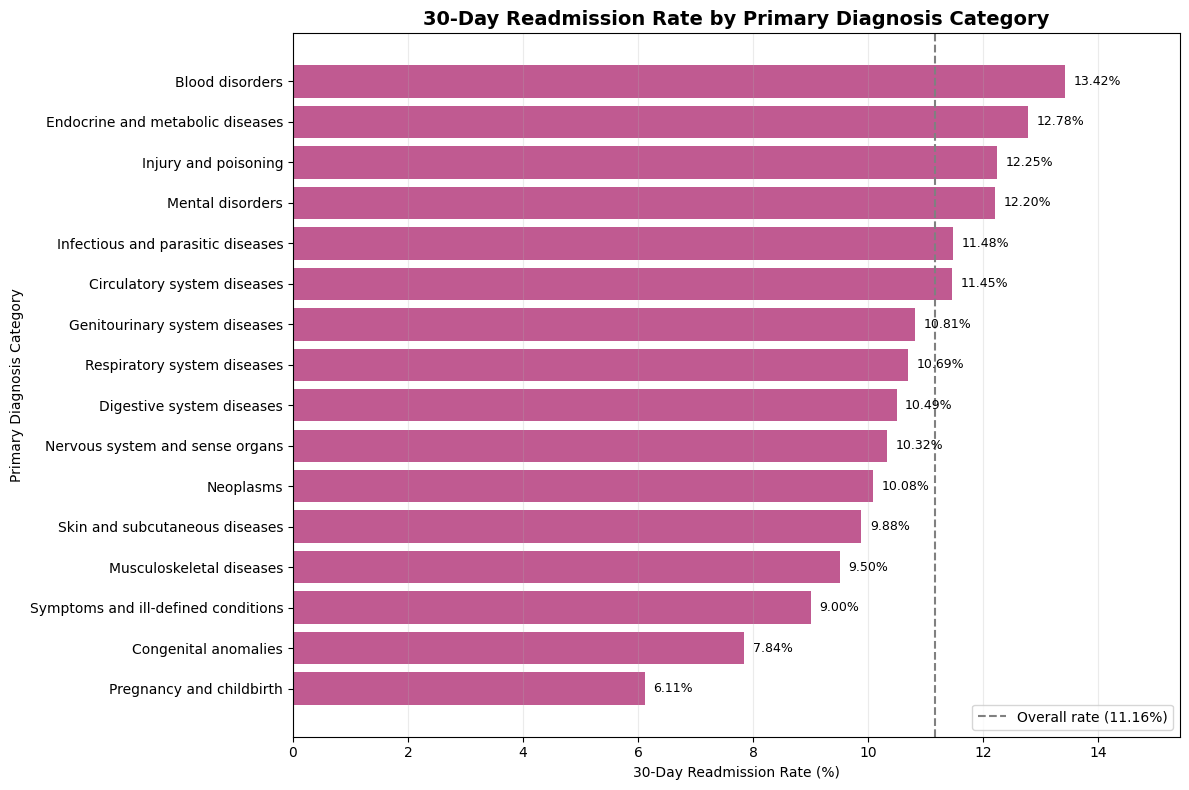

In [54]:

# Plot 30-day readmission rates by primary diagnosis category

special_categories = [
    "Missing",
    "Unclassified",
    "V codes",
    "E codes"
]

# Filter only for visualization
plot_data = (
    diagnosis_summary.loc[
        ~diagnosis_summary["primary_diagnosis_category"]
        .isin(special_categories)
    ]
    .sort_values("readmission_rate")
)

plt.figure(figsize=(12, 8))

bars = plt.barh(
    plot_data["primary_diagnosis_category"],
    plot_data["readmission_rate"],
    color="#C05A91"
)

# Display percentage labels beside each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        fontsize=9
    )

# Add overall readmission rate reference line
plt.axvline(
    x=overall_readmission_rate,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall rate ({overall_readmission_rate:.2f}%)"
)

plt.title(
    "30-Day Readmission Rate by Primary Diagnosis Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("30-Day Readmission Rate (%)")
plt.ylabel("Primary Diagnosis Category")

plt.xlim(0, plot_data["readmission_rate"].max() + 2)
plt.grid(axis="x", alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()


#### Primary Diagnosis Category Visualization: Limitations

- Exclusion of supplementary and unclassified codes: The visualization includes only the 16 standard ICD-9-CM disease chapters. V codes, E codes, missing diagnoses, and unclassified codes are excluded from the chart but retained in the overall analysis. V codes had a 16.18% readmission rate and are discussed separately in the key findings.

- Unequal sample sizes: Diagnosis categories contain different numbers of encounters. For example, congenital anomalies had only 51 encounters, while infectious and parasitic diseases had 122. Readmission rates calculated from smaller groups may be less stable than those from larger groups.

- Broad diagnosis classification: Primary diagnoses were grouped into ICD-9-CM chapters rather than individual medical conditions. Consequently, each category may include patients with substantially different diagnoses and clinical characteristics.

- Reference limitations: The classification used ICD-9-CM chapter ranges and family-level validation against a 2007 CMS reference. Family-level recognition does not verify every complete diagnosis code, and historical coding differences may exist across the dataset's 1999–2008 period.

- Descriptive associations: Differences in readmission rates do not establish that specific diagnoses cause readmission. Patient characteristics, comorbidities, previous healthcare utilization, and clinical complexity may contribute to the observed differences.

Interpretation: The visualization is intended to compare observed 30-day readmission patterns across broad primary diagnosis categories, not to establish independent clinical risk factors.


In [55]:

print(
    "Total encounters:",
    diagnosis_summary["total_encounters"].sum()
)

print(
    "Total 30-day readmissions:",
    diagnosis_summary["readmissions_30days"].sum()
)

print(
    "Original 30-day readmissions:",
    (df_analysis["readmitted"] == "<30").sum()
)


Total encounters: 101766
Total 30-day readmissions: 11357
Original 30-day readmissions: 11357


### Age and 30-Day Readmission

Does the 30-day readmission rate differ across patient age groups?


In [56]:

age_summary = (
    df_analysis.groupby("age")
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

age_summary["readmission_rate"] *= 100

age_summary.sort_values("age").round(2)


,age,total_encounters,readmissions_30days,readmission_rate
0,[0-10),161,3,1.86
1,[10-20),691,40,5.79
2,[20-30),1657,236,14.24
3,[30-40),3775,424,11.23
4,[40-50),9685,1027,10.60
5,[50-60),17256,1668,9.67
6,[60-70),22483,2502,11.13
7,[70-80),26068,3069,11.77
8,[80-90),17197,2078,12.08
9,[90-100),2793,310,11.10


In [57]:

print("Total encounters:", age_summary["total_encounters"].sum())

print(
    "Total 30-day readmissions:",
    age_summary["readmissions_30days"].sum()
)

print(
    "Original 30-day readmissions:",
    df_analysis["readmitted_30days"].sum()
)


Total encounters: 101766
Total 30-day readmissions: 11357
Original 30-day readmissions: 11357


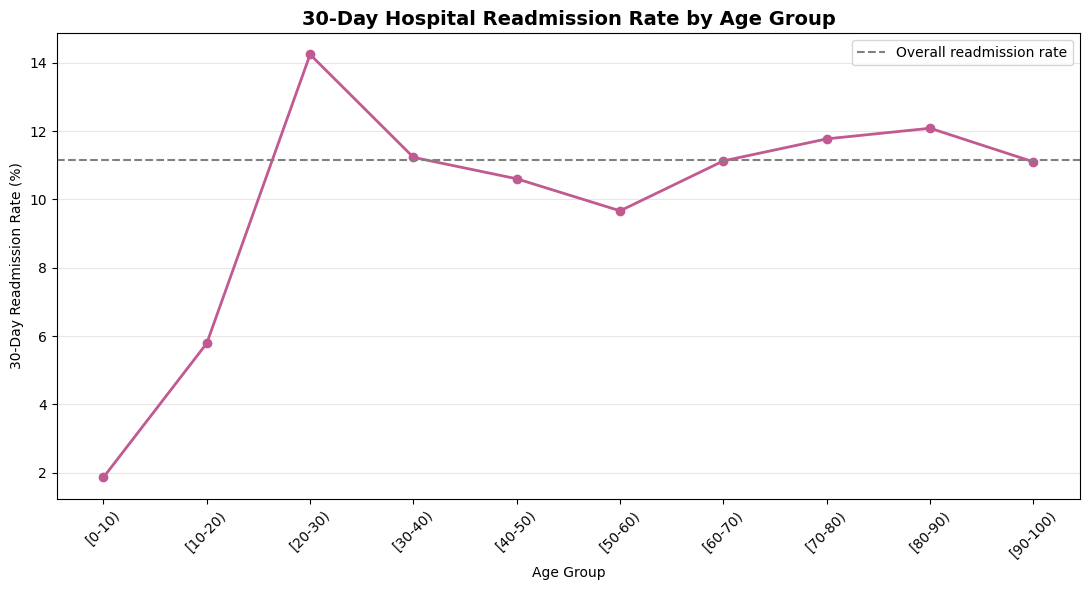

In [58]:

# Ensure age groups are in ascending order
age_summary = age_summary.sort_values("age")

plt.figure(figsize=(11, 6))

plt.plot(
    age_summary["age"],
    age_summary["readmission_rate"],
    marker="o",
    linewidth=2,
    color="#C05A91"
)

plt.title(
    "30-Day Hospital Readmission Rate by Age Group",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Age Group")
plt.ylabel("30-Day Readmission Rate (%)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.axhline(
    y=overall_readmission_rate,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Overall readmission rate"
)

plt.legend()


plt.tight_layout()
plt.show()


#### Age and 30-Day Readmission: Key Findings

The relationship between age and 30-day hospital readmission was non-linear. The 20–30 age group had the highest observed readmission rate (14.24%, 236 of 1,657 encounters), while the 70–80 age group accounted for the largest number of encounters (26,068) and 30-day readmissions (3,069).

Although readmission rates allow comparisons between age groups of different sizes, estimates based on smaller groups may be less stable. Therefore, findings from the youngest age groups should be interpreted cautiously.

These results describe encounter-level associations and do not establish that age independently determines readmission risk.


### Gender and 30-Day Readmission

Do 30-day hospital readmission rates differ between the recorded gender groups?


In [59]:

gender_summary = (
    df_analysis.groupby("gender", dropna=False)
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

gender_summary["readmission_rate"] *= 100

gender_summary.round(2)


,gender,total_encounters,readmissions_30days,readmission_rate
0,Female,54708,6152,11.25
1,Male,47055,5205,11.06
2,NaN,3,0,0.00


In [60]:

print(
    "Total encounters:",
    gender_summary["total_encounters"].sum()
)

print(
    "Grouped 30-day readmissions:",
    gender_summary["readmissions_30days"].sum()
)

print(
    "Original 30-day readmissions:",
    df_analysis["readmitted_30days"].sum()
)


Total encounters: 101766
Grouped 30-day readmissions: 11357
Original 30-day readmissions: 11357


#### Gender and 30-Day Readmission: Key Findings

Female encounters had a slightly higher 30-day readmission rate (11.25%) than male encounters (11.06%), representing a difference of 0.19 percentage points.

Female encounters also accounted for more total encounters (54,708) and 30-day readmissions (6,152) compared with male encounters (47,055 encounters and 5,205 readmissions).

The observed difference in readmission rates was relatively small, suggesting limited separation between the recorded gender groups in this descriptive analysis. These findings do not establish whether gender is independently associated with readmission after accounting for other patient and encounter characteristics.

Three encounters had missing gender information and were retained in the dataset.


### Length of Stay and 30-Day Readmission

Does the 30-day readmission rate vary depending on how many days a patient stays in the hospital?


In [61]:

los_summary = (
    df_analysis.groupby("time_in_hospital")
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
    .sort_values("time_in_hospital")
)

# Convert proportion to percentage
los_summary["readmission_rate"] *= 100

los_summary.round(2)


,time_in_hospital,total_encounters,readmissions_30days,readmission_rate
0,1,14208,1162,8.18
1,2,17224,1712,9.94
2,3,17756,1894,10.67
3,4,13924,1644,11.81
4,5,9966,1199,12.03
5,6,7539,949,12.59
6,7,5859,752,12.83
7,8,4391,625,14.23
8,9,3002,412,13.72
9,10,2342,336,14.35


In [62]:

print("Total encounters:", los_summary["total_encounters"].sum())

print(
    "Grouped readmissions:",
    los_summary["readmissions_30days"].sum()
)

print(
    "Original readmissions:",
    df_analysis["readmitted_30days"].sum()
)


Total encounters: 101766
Grouped readmissions: 11357
Original readmissions: 11357


#### Length of Stay and 30-Day Readmission: Key Findings

The 30-day readmission rate generally increased with hospital length of stay from 1 to 10 days, although the relationship was not strictly linear.

Encounters lasting 10 days had the highest observed readmission rate (14.35%), closely followed by 8-day stays (14.23%). In comparison, encounters lasting 1 day had a readmission rate of 8.18%.

Readmission rates fluctuated among longer hospital stays, particularly from 11 to 14 days. All length-of-stay groups contained more than 1,000 encounters, supporting descriptive comparisons, although estimates for smaller groups may be less precise.

These findings suggest an association between hospital length of stay and 30-day readmission. However, longer stays may reflect greater clinical complexity or illness severity rather than directly contributing to readmission.


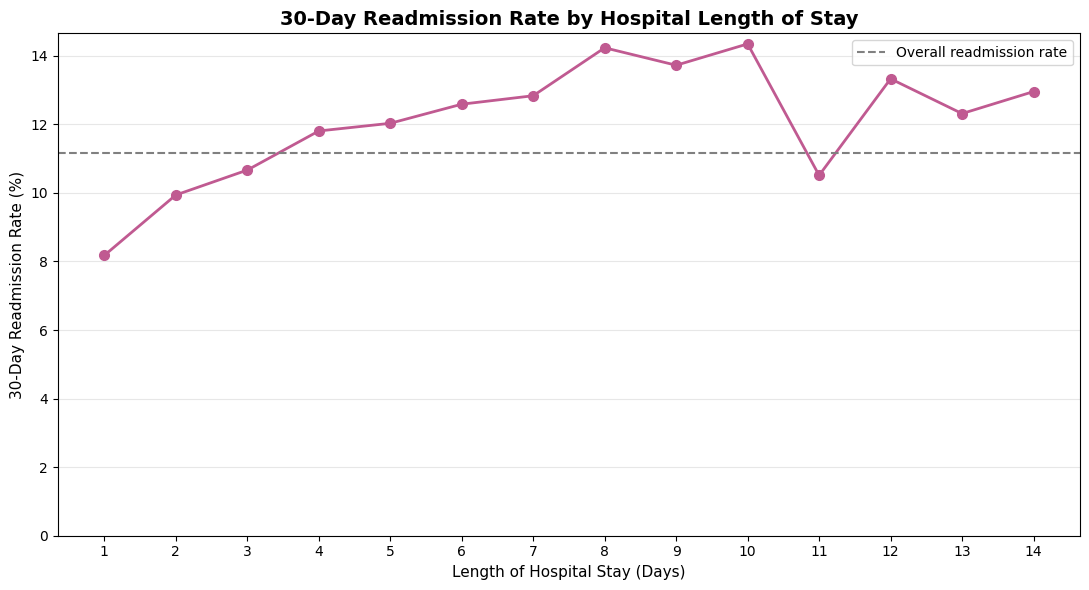

In [63]:

# Plot 30-day readmission rate by length of stay

plt.figure(figsize=(11, 6))

plt.plot(
    los_summary["time_in_hospital"],
    los_summary["readmission_rate"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#C05A91"
)

plt.title(
    "30-Day Readmission Rate by Hospital Length of Stay",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Length of Hospital Stay (Days)", fontsize=11)
plt.ylabel("30-Day Readmission Rate (%)", fontsize=11)

# Display each day on the x-axis
plt.xticks(range(1, 15))

# Start the percentage axis at zero
plt.ylim(bottom=0)

plt.grid(axis="y", alpha=0.3)


plt.axhline(
    y=overall_readmission_rate,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Overall readmission rate"
)

plt.legend()

plt.tight_layout()
plt.show()


### Medication Count and 30-Day Readmission

Are encounters involving more medications associated with higher 30-day readmission rates?


In [64]:

# Create groups of 10 medications
bins = [0, 10, 20, 30, 40, 50, 60, np.inf]

labels = [
    "1-10", "11-20", "21-30", "31-40",
    "41-50", "51-60", "61+"
]

df_analysis["medication_group"] = pd.cut(
    df_analysis["num_medications"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Check the distribution across groups
df_analysis["medication_group"].value_counts().sort_index()


medication_group
1-10     25861
11-20    52025
21-30    18643
31-40     3876
41-50      931
51-60      333
61+         97
Name: count, dtype: int64

In [65]:

medication_summary = (
    df_analysis.groupby(
        "medication_group",
        observed=True
    )
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

medication_summary["readmission_rate"] *= 100

medication_summary.round(2)


,medication_group,total_encounters,readmissions_30days,readmission_rate
0,1-10,25861,2344,9.06
1,11-20,52025,5962,11.46
2,21-30,18643,2400,12.87
3,31-40,3876,497,12.82
4,41-50,931,108,11.60
5,51-60,333,32,9.61
6,61+,97,14,14.43


In [66]:

print(
    "Total encounters:",
    medication_summary["total_encounters"].sum()
)

print(
    "Grouped 30-day readmissions:",
    medication_summary["readmissions_30days"].sum()
)

print(
    "Original 30-day readmissions:",
    df_analysis["readmitted_30days"].sum()
)

print(
    "Missing medication groups:",
    df_analysis["medication_group"].isna().sum()
)


Total encounters: 101766
Grouped 30-day readmissions: 11357
Original 30-day readmissions: 11357
Missing medication groups: 0


#### Number of Medications and 30-Day Readmission: Key Findings

The 30-day readmission rate increased from 9.06% among encounters involving 1–10 medications to 12.87% among encounters involving 21–30 medications.

Although the 61+ medication group had the highest observed readmission rate (14.43%), it contained only 97 encounters and 14 readmissions. This estimate should therefore be interpreted cautiously due to its small sample size.

Readmission rates fluctuated beyond 30 medications rather than showing a consistent increase.

Overall, the results suggest a non-linear association between medication count and 30-day readmission. Medication count may reflect treatment intensity or underlying clinical complexity rather than directly contributing to readmission risk.


### Laboratory Procedures and 30-Day Readmission

Are hospital encounters involving more laboratory procedures associated with higher 30-day readmission rates?


In [67]:

# Group laboratory procedures into intervals

lab_bins = [-1, 20, 40, 60, 80, 100, float("inf")]

lab_labels = [
    "0-20", "21-40", "41-60",
    "61-80", "81-100", "101+"
]

df_analysis["lab_group"] = pd.cut(
    df_analysis["num_lab_procedures"],
    bins=lab_bins,
    labels=lab_labels
)

# Check the number of encounters in each group
df_analysis["lab_group"].value_counts().sort_index()


lab_group
0-20      14536
21-40     27749
41-60     40066
61-80     17475
81-100     1876
101+         64
Name: count, dtype: int64

In [68]:

lab_summary = (
    df_analysis.groupby("lab_group", observed=True)
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

lab_summary["readmission_rate"] *= 100

lab_summary.round(2)


,lab_group,total_encounters,readmissions_30days,readmission_rate
0,0-20,14536,1433,9.86
1,21-40,27749,2960,10.67
2,41-60,40066,4650,11.61
3,61-80,17475,2082,11.91
4,81-100,1876,223,11.89
5,101+,64,9,14.06


In [69]:

print(
    "Total encounters:",
    lab_summary["total_encounters"].sum()
)

print(
    "Grouped 30-day readmissions:",
    lab_summary["readmissions_30days"].sum()
)

print(
    "Original 30-day readmissions:",
    df_analysis["readmitted_30days"].sum()
)

print(
    "Missing lab groups:",
    df_analysis["lab_group"].isna().sum()
)


Total encounters: 101766
Grouped 30-day readmissions: 11357
Original 30-day readmissions: 11357
Missing lab groups: 0


#### Laboratory Procedures and 30-Day Readmission: Key Findings

The 30-day readmission rate generally increased with the number of laboratory procedures performed during hospitalization, rising from 9.86% among encounters with 0–20 procedures to 11.91% among encounters with 61–80 procedures.

Readmission rates were similar between the 61–80 (11.91%) and 81–100 (11.89%) groups, suggesting a possible plateau at higher procedure counts.

Although the 101+ group had the highest observed readmission rate (14.06%), this estimate was based on only 64 encounters and 9 readmissions and should be interpreted cautiously.

Overall, the results indicate a descriptive association between laboratory procedure volume and 30-day readmission. Higher procedure counts may reflect greater clinical complexity or monitoring needs rather than independently increasing readmission risk.


### Non-Laboratory Procedures and 30-Day Readmission

Does the number of non-laboratory procedures performed during hospitalization have an association with 30-day readmission rates?


In [70]:

procedure_summary = (
    df_analysis.groupby("num_procedures")
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
    .sort_values("num_procedures")
)

# Convert proportion to percentage
procedure_summary["readmission_rate"] *= 100

procedure_summary.round(2)


,num_procedures,total_encounters,readmissions_30days,readmission_rate
0,0,46652,5168,11.08
1,1,20742,2532,12.21
2,2,12717,1422,11.18
3,3,9443,1009,10.69
4,4,4180,461,11.03
5,5,3078,290,9.42
6,6,4954,475,9.59


In [71]:

print(
    "Total encounters:",
    procedure_summary["total_encounters"].sum()
)

print(
    "Grouped 30-day readmissions:",
    procedure_summary["readmissions_30days"].sum()
)

print(
    "Original 30-day readmissions:",
    df_analysis["readmitted_30days"].sum()
)

print(
    "Missing procedure values:",
    df_analysis["num_procedures"].isna().sum()
)


Total encounters: 101766
Grouped 30-day readmissions: 11357
Original 30-day readmissions: 11357
Missing procedure values: 0


#### Number of Procedures and 30-Day Readmission: Key Findings

Encounters involving one non-laboratory procedure had the highest observed 30-day readmission rate (12.21%), compared with 11.08% among encounters involving no procedures.

Readmission rates generally declined beyond one procedure, although the pattern fluctuated. Encounters involving five procedures had the lowest observed readmission rate (9.42%).

All procedure-count categories contained more than 3,000 encounters, supporting descriptive comparisons without the extreme sample-size limitations observed in some medication and laboratory procedure groups.

These findings indicate that a higher number of non-laboratory procedures was not consistently associated with higher 30-day readmission rates. The observed differences may reflect variation in patient conditions, types of procedures, and clinical complexity.

Variable interpretation and limitations

The `num_procedures` variable represents the number of non-laboratory procedures recorded during a single hospital encounter. Multiple procedures may occur on the same day or across different days of one continuous hospitalization.

The dataset does not identify the specific procedures performed or their timing. Therefore, procedure count cannot be used to determine surgical complexity, procedure type, or whether procedures occurred on separate days.

The observed association between procedure count and 30-day readmission should be interpreted cautiously, without assuming that performing more procedures directly affects readmission risk.


### Recorded Diagnosis Count and 30-Day Readmission

Are hospital encounters with more recorded diagnoses associated with higher 30-day readmission rates?


In [72]:

# Examine the distribution of recorded diagnosis counts

print(df_analysis["number_diagnoses"].describe())

df_analysis["number_diagnoses"].value_counts().sort_index()


count    101766.000000
mean          7.422607
std           1.933600
min           1.000000
25%           6.000000
50%           8.000000
75%           9.000000
max          16.000000
Name: number_diagnoses, dtype: float64


number_diagnoses
1       219
2      1023
3      2835
4      5537
5     11393
6     10161
7     10393
8     10616
9     49474
10       17
11       11
12        9
13       16
14        7
15       10
16       45
Name: count, dtype: int64

In [73]:

# Group recorded diagnosis counts

df_analysis["diagnosis_count_group"] = (
    df_analysis["number_diagnoses"]
    .apply(lambda x: "10+" if x >= 10 else str(int(x)))
)

# Check group sizes
df_analysis["diagnosis_count_group"].value_counts()


diagnosis_count_group
9      49474
5      11393
8      10616
7      10393
6      10161
4       5537
3       2835
2       1023
1        219
10+      115
Name: count, dtype: int64

In [74]:

diagnosis_count_summary = (
    df_analysis.groupby("diagnosis_count_group")
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

diagnosis_count_summary["readmission_rate"] *= 100

# Display groups in numerical order
group_order = [str(i) for i in range(1, 10)] + ["10+"]

diagnosis_count_summary["diagnosis_count_group"] = pd.Categorical(
    diagnosis_count_summary["diagnosis_count_group"],
    categories=group_order,
    ordered=True
)

diagnosis_count_summary.sort_values(
    "diagnosis_count_group"
).round(2)


,diagnosis_count_group,total_encounters,readmissions_30days,readmission_rate
0,1,219,13,5.94
2,2,1023,62,6.06
3,3,2835,209,7.37
4,4,5537,457,8.25
5,5,11393,1043,9.15
6,6,10161,1058,10.41
7,7,10393,1119,10.77
8,8,10616,1254,11.81
9,9,49474,6125,12.38
1,10+,115,17,14.78


In [75]:

print(
    "Total encounters:",
    diagnosis_count_summary["total_encounters"].sum()
)

print(
    "Grouped readmissions:",
    diagnosis_count_summary["readmissions_30days"].sum()
)

print(
    "Original readmissions:",
    df_analysis["readmitted_30days"].sum()
)

print(
    "Missing diagnosis count groups:",
    df_analysis["diagnosis_count_group"].isna().sum()
)


Total encounters: 101766
Grouped readmissions: 11357
Original readmissions: 11357
Missing diagnosis count groups: 0


#### Number of Recorded Diagnoses and 30-Day Readmission: Key Findings

The 30-day readmission rate increased consistently with the number of recorded diagnoses. Encounters with one diagnosis had a readmission rate of 5.94%, compared with 12.38% among encounters with nine recorded diagnoses.

The 10+ diagnosis group had the highest observed readmission rate (14.78%), but contained only 115 encounters and 17 readmissions, limiting the stability of this estimate.

Nearly half of all encounters (48.62%) had exactly nine recorded diagnoses. This concentration may reflect characteristics or limitations of diagnosis reporting in the source dataset and warrants caution when interpreting higher diagnosis counts.

Overall, the results show a positive descriptive association between the number of recorded diagnoses and 30-day readmission. The number of documented diagnoses may reflect clinical complexity but should not be treated as a validated measure of illness severity.


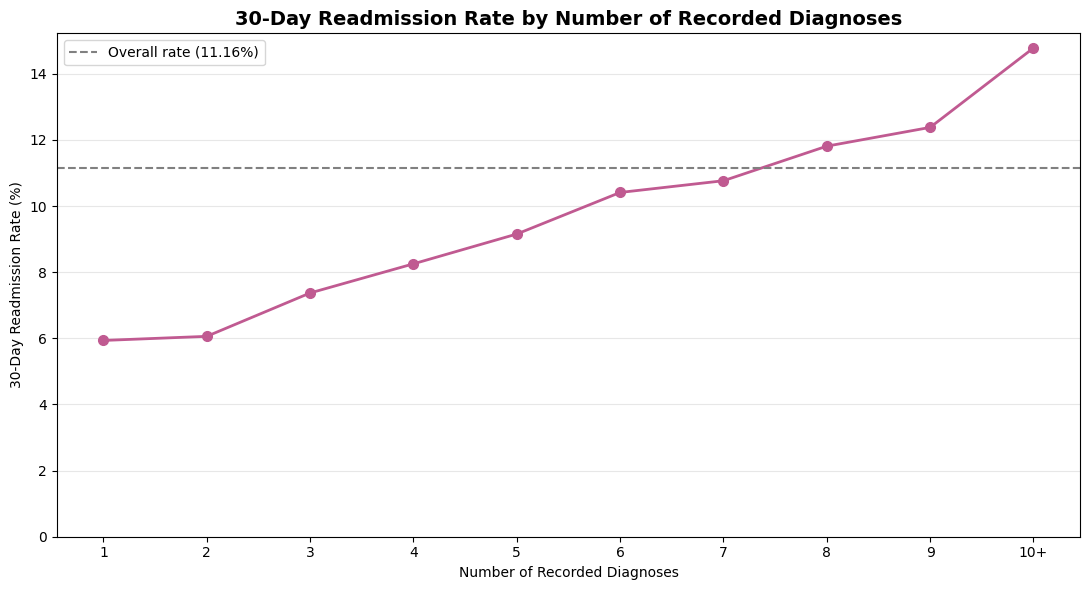

In [76]:

# Plot readmission rate by number of recorded diagnoses

diagnosis_plot = diagnosis_count_summary.sort_values(
    "diagnosis_count_group"
)

plt.figure(figsize=(11, 6))

plt.plot(
    diagnosis_plot["diagnosis_count_group"].astype(str),
    diagnosis_plot["readmission_rate"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="#C05A91"
)

plt.axhline(
    y=overall_readmission_rate,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall rate ({overall_readmission_rate:.2f}%)"
)

plt.title(
    "30-Day Readmission Rate by Number of Recorded Diagnoses",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Recorded Diagnoses")
plt.ylabel("30-Day Readmission Rate (%)")

plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


## Previous Healthcare Utilization


In [77]:

# Examine distribution of previous inpatient visits

print(df_analysis["number_inpatient"].describe())

df_analysis["number_inpatient"].value_counts().sort_index()


count    101766.000000
mean          0.635566
std           1.262863
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          21.000000
Name: number_inpatient, dtype: float64


number_inpatient
0     67630
1     19521
2      7566
3      3411
4      1622
5       812
6       480
7       268
8       151
9       111
10       61
11       49
12       34
13       20
14       10
15        9
16        6
17        1
18        1
19        2
21        1
Name: count, dtype: int64

In [78]:

# Group previous inpatient visits

inpatient_bins = [-1, 0, 1, 2, 3, float("inf")]

inpatient_labels = ["0", "1", "2", "3", "4+"]

df_analysis["inpatient_group"] = pd.cut(
    df_analysis["number_inpatient"],
    bins=inpatient_bins,
    labels=inpatient_labels
)

# Check group sizes
df_analysis["inpatient_group"].value_counts().sort_index()


inpatient_group
0     67630
1     19521
2      7566
3      3411
4+     3638
Name: count, dtype: int64

In [79]:

inpatient_summary = (
    df_analysis.groupby("inpatient_group", observed=True)
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

inpatient_summary["readmission_rate"] *= 100

inpatient_summary.round(2)


,inpatient_group,total_encounters,readmissions_30days,readmission_rate
0,0,67630,5706,8.44
1,1,19521,2523,12.92
2,2,7566,1319,17.43
3,3,3411,692,20.29
4,4+,3638,1117,30.70


In [80]:

print(
    "Total encounters:",
    inpatient_summary["total_encounters"].sum()
)

print(
    "Grouped readmissions:",
    inpatient_summary["readmissions_30days"].sum()
)

print(
    "Original readmissions:",
    df_analysis["readmitted_30days"].sum()
)

print(
    "Missing inpatient groups:",
    df_analysis["inpatient_group"].isna().sum()
)


Total encounters: 101766
Grouped readmissions: 11357
Original readmissions: 11357
Missing inpatient groups: 0


#### Previous Inpatient Visits and 30-Day Readmission: Key Findings

The 30-day readmission rate increased consistently with the number of inpatient visits recorded in the year preceding the current encounter.

Encounters with no previous inpatient visits had a readmission rate of 8.44%, compared with 12.92% for one previous visit, 17.43% for two visits, 20.29% for three visits, and 30.70% for four or more visits.

Although encounters with no previous inpatient visits accounted for the largest number of encounters (67,630), they had the lowest readmission rate.

These findings suggest a strong descriptive association between prior inpatient utilization and subsequent 30-day readmission. However, the analysis does not establish causation, and differences in underlying patient health and clinical complexity may contribute to the observed pattern.


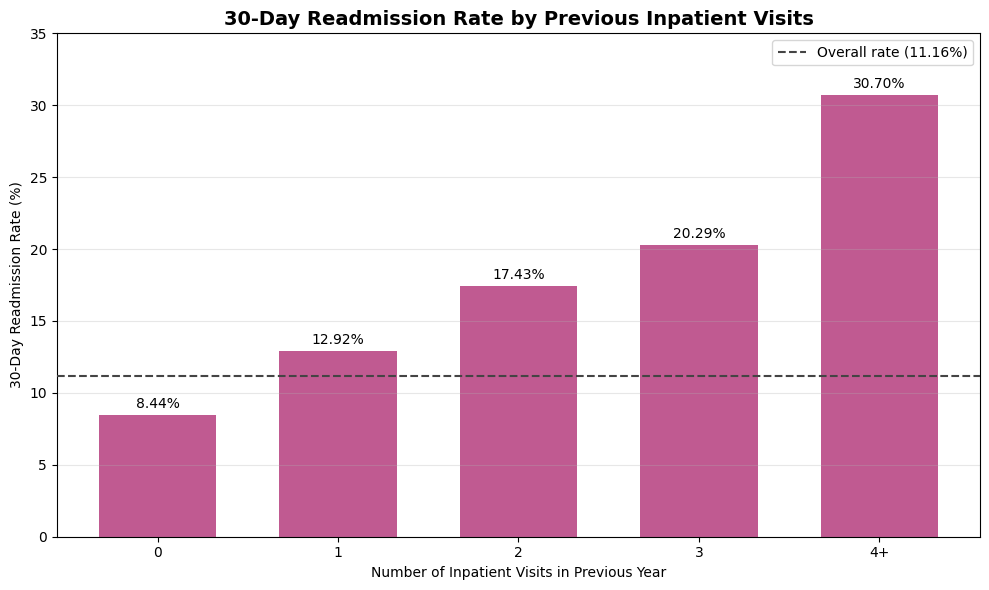

In [81]:

# Plot readmission rate by previous inpatient visits

plt.figure(figsize=(10, 6))

plt.bar(
    inpatient_summary["inpatient_group"].astype(str),
    inpatient_summary["readmission_rate"],
    color="#C05A91",
    width=0.65
)

# Add readmission percentage labels above bars
for i, rate in enumerate(inpatient_summary["readmission_rate"]):
    plt.text(
        i,
        rate + 0.5,
        f"{rate:.2f}%",
        ha="center",
        fontsize=10
    )

plt.axhline(
    y=overall_readmission_rate,
    color="#444444",
    linestyle="--",
    linewidth=1.5,
    zorder=5,
    label=f"Overall rate ({overall_readmission_rate:.2f}%)"
)

plt.title(
    "30-Day Readmission Rate by Previous Inpatient Visits",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Inpatient Visits in Previous Year")
plt.ylabel("30-Day Readmission Rate (%)")

plt.ylim(0, 35)
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


In [82]:

# Examine previous emergency visit distribution

print(df_analysis["number_emergency"].describe())

df_analysis["number_emergency"].value_counts().sort_index()


count    101766.000000
mean          0.197836
std           0.930472
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          76.000000
Name: number_emergency, dtype: float64


number_emergency
0     90383
1      7677
2      2042
3       725
4       374
5       192
6        94
7        73
8        50
9        33
10       34
11       23
12       10
13       12
14        3
15        3
16        5
18        5
19        4
20        4
21        2
22        6
24        1
25        2
28        1
29        1
37        1
42        1
46        1
54        1
63        1
64        1
76        1
Name: count, dtype: int64

In [83]:

# Group previous emergency visits

emergency_bins = [-1, 0, 1, 2, float("inf")]
emergency_labels = ["0", "1", "2", "3+"]

df_analysis["emergency_group"] = pd.cut(
    df_analysis["number_emergency"],
    bins=emergency_bins,
    labels=emergency_labels
)

# Check the number of encounters in each group
df_analysis["emergency_group"].value_counts().sort_index()


emergency_group
0     90383
1      7677
2      2042
3+     1664
Name: count, dtype: int64

In [84]:

emergency_summary = (
    df_analysis.groupby("emergency_group", observed=True)
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

emergency_summary["readmission_rate"] *= 100

emergency_summary.round(2)


,emergency_group,total_encounters,readmissions_30days,readmission_rate
0,0,90383,9467,10.47
1,1,7677,1102,14.35
2,2,2042,373,18.27
3,3+,1664,415,24.94


In [85]:

print("Total encounters:", emergency_summary["total_encounters"].sum())

print(
    "Grouped readmissions:",
    emergency_summary["readmissions_30days"].sum()
)

print(
    "Original readmissions:",
    df_analysis["readmitted_30days"].sum()
)

print(
    "Missing emergency groups:",
    df_analysis["emergency_group"].isna().sum()
)


Total encounters: 101766
Grouped readmissions: 11357
Original readmissions: 11357
Missing emergency groups: 0


#### Previous Emergency Visits and 30-Day Readmission: Key Findings

The 30-day readmission rate increased consistently with the number of emergency visits recorded in the year preceding the current hospital encounter.

Encounters with no previous emergency visits had a readmission rate of 10.47%, compared with 14.35% for one visit, 18.27% for two visits, and 24.94% for three or more visits.

Although encounters with no previous emergency visits accounted for the largest number of encounters (90,383) and readmissions (9,467), they had the lowest readmission rate.

These findings indicate a positive descriptive association between previous emergency department utilization and 30-day readmission. Differences in underlying health conditions and healthcare needs may contribute to this association.


In [86]:

# Examine distribution of previous outpatient visits

print(df_analysis["number_outpatient"].describe())

df_analysis["number_outpatient"].value_counts().sort_index()


count    101766.000000
mean          0.369357
std           1.267265
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          42.000000
Name: number_outpatient, dtype: float64


number_outpatient
0     85027
1      8547
2      3594
3      2042
4      1099
5       533
6       303
7       155
8        98
9        83
10       57
11       42
12       30
13       31
14       28
15       20
16       15
17        8
18        5
19        3
20        7
21        7
22        5
23        2
24        3
25        2
26        2
27        3
28        1
29        2
33        2
34        1
35        2
36        2
37        1
38        1
39        1
40        1
42        1
Name: count, dtype: int64

In [87]:

# Group previous outpatient visits

outpatient_bins = [-1, 0, 1, 2, float("inf")]
outpatient_labels = ["0", "1", "2", "3+"]

df_analysis["outpatient_group"] = pd.cut(
    df_analysis["number_outpatient"],
    bins=outpatient_bins,
    labels=outpatient_labels
)

# Check the number of encounters in each group
df_analysis["outpatient_group"].value_counts().sort_index()


outpatient_group
0     85027
1      8547
2      3594
3+     4598
Name: count, dtype: int64

In [88]:

outpatient_summary = (
    df_analysis.groupby("outpatient_group", observed=True)
    .agg(
        total_encounters=("encounter_id", "count"),
        readmissions_30days=("readmitted_30days", "sum"),
        readmission_rate=("readmitted_30days", "mean")
    )
    .reset_index()
)

outpatient_summary["readmission_rate"] *= 100

outpatient_summary.round(2)


,outpatient_group,total_encounters,readmissions_30days,readmission_rate
0,0,85027,9076,10.67
1,1,8547,1190,13.92
2,2,3594,494,13.75
3,3+,4598,597,12.98


In [89]:

print(
    "Total encounters:",
    outpatient_summary["total_encounters"].sum()
)

print(
    "Grouped readmissions:",
    outpatient_summary["readmissions_30days"].sum()
)

print(
    "Original readmissions:",
    df_analysis["readmitted_30days"].sum()
)

print(
    "Missing outpatient groups:",
    df_analysis["outpatient_group"].isna().sum()
)


Total encounters: 101766
Grouped readmissions: 11357
Original readmissions: 11357
Missing outpatient groups: 0


#### Previous Outpatient Visits and 30-Day Readmission: Key Findings

Encounters with one previous outpatient visit had the highest observed 30-day readmission rate (13.92%), followed by two visits (13.75%) and three or more visits (12.98%).

Encounters with no previous outpatient visits had the lowest readmission rate (10.67%), despite accounting for the largest number of encounters and readmissions.

Unlike previous inpatient and emergency visits, which demonstrated consistently increasing readmission rates across the selected utilization categories, outpatient visits showed an initial increase followed by relatively stable, slightly declining rates.

These findings suggest that different types of prior healthcare utilization have distinct descriptive associations with 30-day hospital readmission. The results do not establish causal relationships.


### Comparison of Prior Healthcare Utilization and 30-Day Readmission

To compare how different types of prior healthcare utilization relate to 30-day readmission, I visualized readmission rates across grouped counts of previous inpatient, emergency, and outpatient visits.

This comparison helps show whether prior utilization patterns are similarly associated with readmission risk, or whether some utilization measures appear more strongly associated than others.

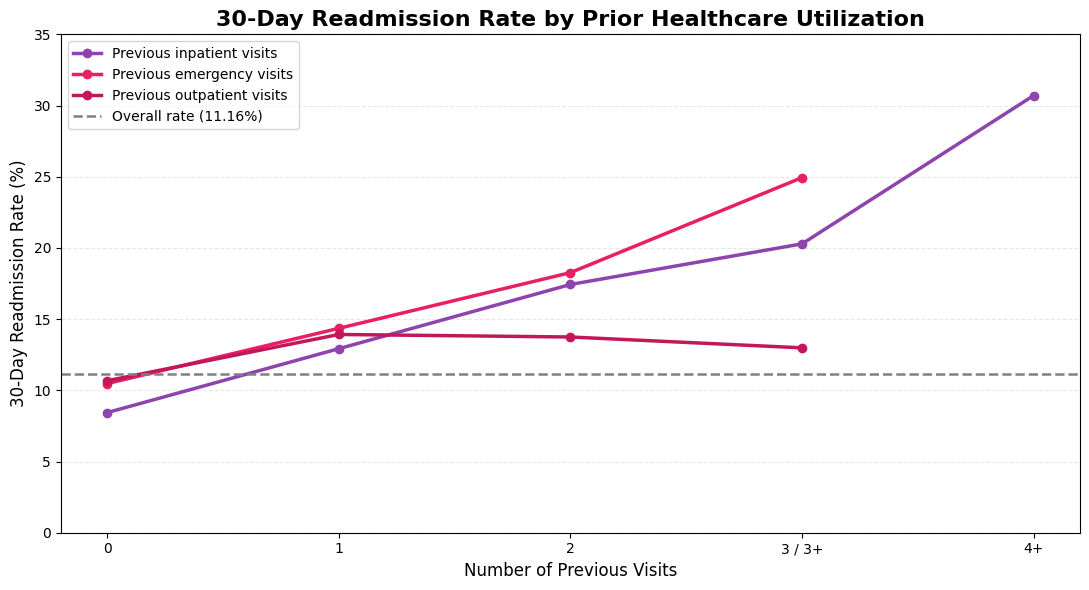

In [90]:

# Comparison dataframe

comparison_df = pd.DataFrame({
    "group": ["0", "1", "2", "3 / 3+", "4+"],
    "Inpatient": inpatient_summary["readmission_rate"].to_numpy(),
    "Emergency": list(emergency_summary["readmission_rate"]) + [None],
    "Outpatient": list(outpatient_summary["readmission_rate"]) + [None]
})


# Plot
plt.figure(figsize=(11, 6))

plt.plot(
    comparison_df["group"],
    comparison_df["Inpatient"],
    marker="o",
    linewidth=2.5,
    color="#8E44AD",
    label="Previous inpatient visits"
)

plt.plot(
    comparison_df["group"],
    comparison_df["Emergency"],
    marker="o",
    linewidth=2.5,
    color="#E91E63",
    label="Previous emergency visits"
)

plt.plot(
    comparison_df["group"],
    comparison_df["Outpatient"],
    marker="o",
    linewidth=2.5,
    color="#C2185B",
    label="Previous outpatient visits"
)


plt.axhline(
    y=overall_readmission_rate,
    linestyle="--",
    linewidth=1.8,
    color="gray",
    label=f"Overall rate ({overall_readmission_rate:.2f}%)"
)


plt.title(
    "30-Day Readmission Rate by Prior Healthcare Utilization",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Number of Previous Visits", fontsize=12)
plt.ylabel("30-Day Readmission Rate (%)", fontsize=12)

plt.ylim(0, 35)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

#### Prior Healthcare Utilization: Chart Interpretation

The chart shows that prior inpatient and emergency utilization have the strongest positive relationship with 30-day readmission. Readmission rates rise steadily as the number of prior inpatient and emergency visits increases, with inpatient visits showing the steepest increase overall. In contrast, prior outpatient utilization is associated with higher readmission than no outpatient visits, but the pattern levels off after the first visit.

## Cross-Variable Analysis: Previous Inpatient Visits and Recorded Diagnoses

### Objective

The initial descriptive analysis identified two notable patterns:

- The 30-day readmission rate increased from 8.44% among encounters with no previous inpatient visits to 30.70% among encounters with four or more previous inpatient visits.
- The readmission rate also increased with the number of recorded diagnoses, from 5.94% for one diagnosis to 12.38% for nine diagnoses.

This analysis explores whether these two characteristics overlap and how their combinations relate to 30-day readmission.

The objective is to identify descriptive patterns, not to establish causation or independent predictors of readmission.

In [91]:

# Examine recorded diagnosis counts by previous inpatient visits

inpatient_diagnosis_summary = (
    df_analysis.groupby("inpatient_group", observed=True)
    .agg(
        total_encounters=("encounter_id", "count"),
        mean_diagnoses=("number_diagnoses", "mean"),
        median_diagnoses=("number_diagnoses", "median")
    )
    .reset_index()
)

inpatient_diagnosis_summary.round(2)


,inpatient_group,total_encounters,mean_diagnoses,median_diagnoses
0,0,67630,7.24,8.0
1,1,19521,7.70,9.0
2,2,7566,7.89,9.0
3,3,3411,7.94,9.0
4,4+,3638,7.89,9.0


#### Previous Inpatient Visits and Recorded Diagnoses: Initial Findings

The average number of recorded diagnoses generally increased with previous inpatient utilization, although the differences were relatively small.

Encounters with no previous inpatient visits had an average of 7.24 recorded diagnoses, compared with 7.70 for one previous visit, 7.89 for two visits, and 7.94 for three visits. The average declined slightly to 7.89 among encounters with four or more previous visits.

The median number of diagnoses was eight for encounters with no previous inpatient visits and nine for all groups with at least one previous visit.

**Interpretation:** These findings suggest a modest positive descriptive relationship between previous inpatient utilization and the number of recorded diagnoses, with the average diagnosis count leveling off among encounters with multiple previous visits.

However, the concentration of encounters with exactly nine recorded diagnoses limits how much variation this measure can capture. These summary statistics alone are insufficient to establish the strength of the relationship.

**Next step:** Examine 30-day readmission rates across combinations of previous inpatient visits and recorded diagnosis counts to determine whether the patterns observed in our individual analyses persist within these subgroups.


In [92]:

# Readmission rates by previous inpatient visits
# and number of recorded diagnoses

combined_readmission = pd.pivot_table(
    df_analysis,
    index="diagnosis_count_group",
    columns="inpatient_group",
    values="readmitted_30days",
    aggfunc="mean",
    observed=True
) * 100

combined_readmission.round(2)


inpatient_group,0,1,2,3,4+
diagnosis_count_group,,,,,
1,2.14,22.22,20.00,20.00,75.00
10+,14.29,13.79,15.38,25.00,16.67
2,4.44,7.22,19.35,12.50,37.50
3,5.73,8.45,22.22,19.51,36.54
4,6.26,10.69,17.65,21.82,31.54
5,7.15,11.57,16.58,19.34,32.92
6,7.56,12.91,18.56,22.83,31.90
7,8.25,12.64,18.64,21.31,30.95
8,8.93,14.00,17.92,24.84,30.39


In [93]:

# Count encounters in each combination

combined_counts = pd.pivot_table(
    df_analysis,
    index="diagnosis_count_group",
    columns="inpatient_group",
    values="encounter_id",
    aggfunc="count",
    observed=True,
    fill_value=0
)

combined_counts


inpatient_group,0,1,2,3,4+
diagnosis_count_group,,,,,
1,187,18,5,5,4
10+,63,29,13,4,6
2,855,97,31,16,24
3,2285,367,90,41,52
4,4281,795,221,110,130
5,8490,1823,597,243,240
6,7117,1774,668,276,326
7,7178,1938,692,291,294
8,7052,2086,798,318,362


#### Previous Inpatient Visits, Recorded Diagnoses, and 30-Day Readmission: Key Findings

The cross-variable analysis showed that 30-day readmission rates generally increased with previous inpatient utilization, even among encounters with the same number of recorded diagnoses.

Among encounters with nine recorded diagnoses, the readmission rate increased from 9.59% for zero previous inpatient visits to 30.00% for four or more previous visits.

Although encounters with one recorded diagnosis and four or more previous inpatient visits had the highest observed readmission rate (75.00%), this was based on only four encounters and should be interpreted cautiously.

Overall, the findings suggest a positive descriptive association between previous inpatient utilization and 30-day readmission across diagnosis-count groups. However, differences in patient characteristics and clinical complexity may contribute to this pattern, and the results do not establish an independent or causal relationship.


In [94]:

# Mask readmission rates based on very small subgroups

combined_readmission_plot = combined_readmission.where(
    combined_counts >= 30
)

combined_readmission_plot.round(2)


inpatient_group,0,1,2,3,4+
diagnosis_count_group,,,,,
1,2.14,NaN,NaN,NaN,NaN
10+,14.29,NaN,NaN,NaN,NaN
2,4.44,7.22,19.35,NaN,NaN
3,5.73,8.45,22.22,19.51,36.54
4,6.26,10.69,17.65,21.82,31.54
5,7.15,11.57,16.58,19.34,32.92
6,7.56,12.91,18.56,22.83,31.90
7,8.25,12.64,18.64,21.31,30.95
8,8.93,14.00,17.92,24.84,30.39


### Visualization: 30-Day Readmission by Previous Inpatient Visits and Recorded Diagnoses

This heatmap compares 30-day readmission rates across combinations of previous inpatient visits and recorded diagnosis counts. Cells with fewer than 30 encounters are hidden to avoid emphasizing unstable estimates.

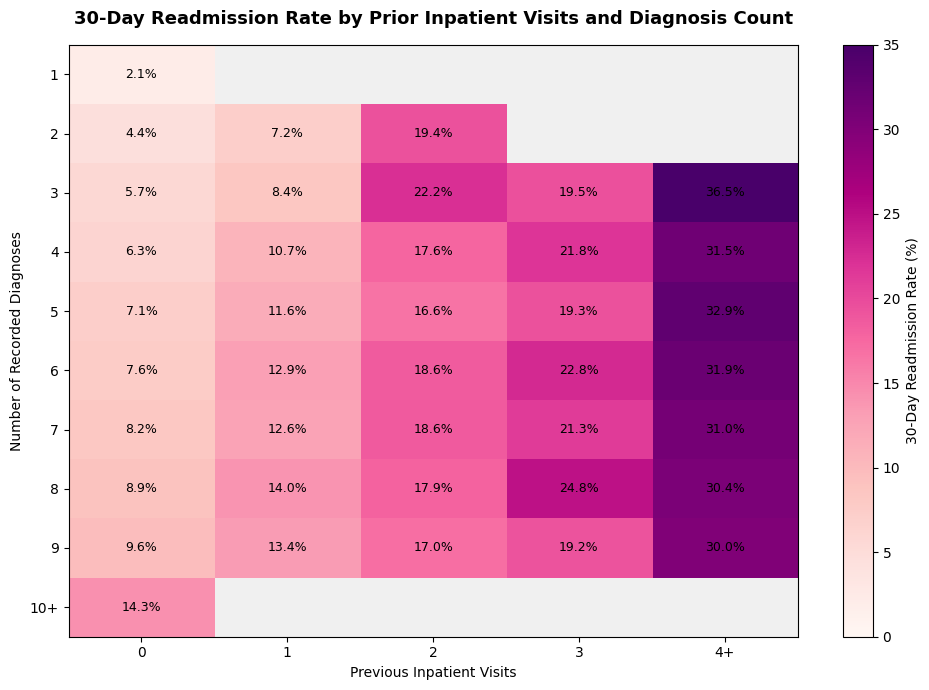

In [95]:

# Use the masked readmission-rate table
diagnosis_order = [str(i) for i in range(1, 10)] + ["10+"]

heatmap_data = (
    combined_readmission_plot
    .reindex(diagnosis_order)
    .astype(float)
)

fig, ax = plt.subplots(figsize=(10, 7))

# Create pink heatmap
cmap = plt.get_cmap("RdPu").copy()
cmap.set_bad(color="#F0F0F0")

im = ax.imshow(
    heatmap_data,
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=35
)

# Label rows and columns
ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns.astype(str))

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index.astype(str))

# Display readmission rates inside cells
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        value = heatmap_data.iloc[i, j]

        if not np.isnan(value):
            ax.text(
                j, i, f"{value:.1f}%",
                ha="center", va="center",
                fontsize=9
            )

# Add color scale
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("30-Day Readmission Rate (%)")

ax.set_title(
    "30-Day Readmission Rate by Prior Inpatient Visits and Diagnosis Count",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Previous Inpatient Visits")
ax.set_ylabel("Number of Recorded Diagnoses")

plt.tight_layout()
plt.show()


#### Cross-Variable Heatmap: Interpretation and Limitations

The heatmap shows that 30-day readmission rates generally increase with previous inpatient utilization across diagnosis-count groups. Higher readmission rates are particularly noticeable among encounters with four or more previous inpatient visits.

Within encounters with no previous inpatient visits, readmission rates also generally increase with the number of recorded diagnoses.

Cells containing fewer than 30 encounters were masked to avoid emphasizing unstable estimates. These records remain included in the underlying dataset and analysis.

Overall, the visualization supports the observed association between previous inpatient utilization, recorded diagnosis counts, and 30-day readmission. However, these are descriptive relationships and do not establish independent or causal effects.


## Final Findings, Limitations, and Conclusion

### Overall Key Findings

This analysis examined 101,766 hospital encounters involving patients with diabetes, of which 11,357 (11.16%) were followed by readmission within 30 days.

Previous inpatient utilization showed one of the clearest associations with readmission. The readmission rate increased from 8.44% among encounters with no previous inpatient visits to 30.70% among those with four or more visits. Previous emergency utilization showed a similar increasing pattern, while outpatient utilization showed an initial increase followed by relatively stable rates.

The number of recorded diagnoses was also positively associated with readmission. Rates increased from 5.94% among encounters with one recorded diagnosis to 12.38% among those with nine diagnoses. Cross-variable analysis showed that higher previous inpatient utilization was generally associated with higher readmission rates even within the same diagnosis-count groups.

Readmission rates also varied across primary diagnosis categories, age groups, and hospital encounter characteristics. Among standard ICD-9-CM disease chapters, blood disorders had the highest observed readmission rate (13.42%), while circulatory system diseases accounted for the greatest number of readmissions (3,474). Length of stay, medication count, and laboratory procedure count showed generally increasing rates over portions of their observed ranges.

Gender showed relatively little difference in readmission rates, with 11.25% among female encounters and 11.06% among male encounters.

Overall, previous healthcare utilization and documented diagnosis burden demonstrated the clearest descriptive patterns associated with 30-day readmission in this analysis.

### Study Limitations

This analysis used observational hospital encounter data from 130 U.S. hospitals collected between 1999 and 2008. Consequently, the findings may not reflect current healthcare practices, patient populations, or readmission patterns.

The analysis was conducted at the encounter level, and some patients contributed multiple encounters. Therefore, observations may not be statistically independent.

Primary diagnoses were grouped into broad ICD-9-CM categories, which may contain clinically diverse conditions. Some diagnosis codes could not be reliably classified, while certain variables contained substantial missing information and were excluded from the primary analysis.

Several categories contained relatively few encounters, making their readmission-rate estimates less stable. Additionally, the concentration of encounters with exactly nine recorded diagnoses may reflect limitations in diagnosis documentation.

The analysis examined descriptive associations rather than adjusted relationships. Differences in age, underlying health conditions, clinical complexity, and prior healthcare utilization may contribute to the observed patterns.

Therefore, the findings should not be interpreted as evidence of causation or as validated independent predictors of readmission.

### Conclusion

The analysis identified differences in 30-day readmission rates across patient characteristics, primary diagnosis categories, hospital encounter factors, and previous healthcare utilization.

Previous inpatient and emergency visits showed particularly clear positive associations with readmission, while a higher number of recorded diagnoses was also associated with increased rates. Cross-variable analysis suggested that the relationship between previous inpatient utilization and readmission persisted across several diagnosis-count groups.

These findings highlight the potential value of examining prior healthcare utilization and documented clinical complexity when investigating hospital readmission patterns among patients with diabetes.

Further analysis incorporating additional patient characteristics and statistical adjustment would be needed to determine whether these relationships remain after accounting for potential confounding factors.

Overall, the project demonstrates how data cleaning, clinical classification, exploratory analysis, validation, and visualization can be used to identify and communicate meaningful patterns in healthcare data.